# Week 3 - Centralised baselines for WISDM (watch accel + gyro)

All outputs are written to `WISDM_baseline_outputs/`.

In [1]:
# Environment setup (only needed once per machine / environment)
!pip install pandas
!pip install numpy
%pip install torch --index-url https://download.pytorch.org/whl/cpu
!pip install matplotlib
!pip install scikit-learn
%pip install polars
%pip install pyarrow

Looking in indexes: https://download.pytorch.org/whl/cpu
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import json, copy, random, time, warnings
import joblib                      # saves / loads scikit-learn objects (scaler, logistic model)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import accuracy_score, f1_score, recall_score, confusion_matrix

# ---- Paths --------------------------------------------------------------
# The notebook lives in the project root, so every input is found relative to the
# folder Jupyter was started from. On another machine (laptop / Mini-PC) you only
# need to change PROJECT if you open the notebook from a different folder.
PROJECT       = Path.cwd()
FEATURE_TABLE = PROJECT / "features_watch.parquet"   # Week 2 output: one row per 10 s watch window
FEATURE_LIST  = PROJECT / "feature_columns.csv"      # Week 2 output: explicit, ordered feature allowlist
SPLIT_FILE    = PROJECT / "split_manifest.csv"       # Week 2 output: frozen participant split (seed 42)
OUTPUT        = PROJECT / "WISDM_baseline_outputs"   # every file this notebook writes goes here
OUTPUT.mkdir(exist_ok=True)

for f in (FEATURE_TABLE, FEATURE_LIST, SPLIT_FILE):
    assert f.exists(), f"Missing input file: {f}  (is PROJECT pointing at the repo root?)"

# ---- Labels ---------------------------------------------------------------
# WISDM uses activity codes A-S with no 'N'. We FREEZE all 18 codes and their
# integer IDs here. Metrics always use all 18 IDs, even if the subset being scored
# is missing a class, so scores from different subsets stay comparable.
LABELS = ['A','B','C','D','E','F','G','H','I',
          'J','K','L','M','O','P','Q','R','S']
LABEL_TO_ID = {code: i for i, code in enumerate(LABELS)}   # 'A' -> 0, ..., 'S' -> 17
LABEL_IDS   = list(range(len(LABELS)))                     # [0, 1, ..., 17]
assert len(LABELS) == 18 and len(set(LABELS)) == 18

# ---- Model / training settings (Week 3 protocol) ---------------------------
SEED            = 42
HIDDEN          = 128            # MLP shape is 30 -> 128 -> 18
BATCH_SIZE      = 64
MAX_EPOCHS      = 50
LEARNING_RATES  = [0.01, 0.03, 0.05]  
LOGREG_C        = 1.0
LOGREG_MAX_ITER = 1000

def set_seed(seed=SEED):
    # Seed every random number generator we use so that runs are repeatable.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed()
torch.set_num_threads(1)   # single thread: a little slower, but identical results on PC, laptop and Mini-PC

print("Project folder :", PROJECT)
print("Outputs go to  :", OUTPUT)
print("torch", torch.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

Project folder : C:\Users\Daniel Busing\Desktop\Personal\China-Internship\NCP-Wearables
Outputs go to  : C:\Users\Daniel Busing\Desktop\Personal\China-Internship\NCP-Wearables\WISDM_baseline_outputs
torch 2.15.0+cpu | numpy 2.4.6 | pandas 3.1.1


## Load and verify the data

### Load the feature table, the ordered feature allowlist and the participant split
The model only ever sees the 30 allowlisted columns, in the order of `feature_columns.csv`
(15 accelerometer + 15 gyroscope features: mean, population std, min, max and RMS per axis).
Everything else in the table (`Subject_ID`, `t_start`, raw line numbers, ...) is metadata kept for tracing only.

In [3]:
frame = pd.read_parquet(FEATURE_TABLE)

# Ordered feature allowlist -> this list fixes the column order of X everywhere.
FEATURES = pd.read_csv(FEATURE_LIST)["features"].tolist()
assert len(FEATURES) == 30, len(FEATURES)
assert set(FEATURES) <= set(frame.columns), "feature table is missing allowlisted columns"
METADATA = [c for c in frame.columns if c not in FEATURES]
print(f"Model inputs  : {len(FEATURES)} features")
print(f"Metadata kept : {METADATA}")

# Main route: watch accelerometer + gyroscope only.
assert (frame["Device"] == "watch").all()
assert (frame["feature_mode"] == "watch_accel_gyro").all()

# split_manifest.csv is in "long" format: one row per participant -> (Subject_ID, split, seed).
manifest = pd.read_csv(SPLIT_FILE)
manifest["split"] = manifest["split"].replace({"eval": "validation"})   # Week 2 called it "eval"
assert manifest["Subject_ID"].is_unique, "a participant appears twice in the split manifest"
assert (manifest["seed"] == SEED).all()
SPLIT_OF_USER = dict(zip(manifest["Subject_ID"], manifest["split"]))
USERS = {s: sorted(manifest.loc[manifest.split == s, "Subject_ID"]) for s in ["train", "validation", "test"]}
print("Participants per split:", {s: len(u) for s, u in USERS.items()})

Model inputs  : 30 features
Metadata kept : ['window_id', 'pair_id', 'Subject_ID', 'Device', 'Activity_Code', 'occ', 'split', 't_start', 'acc_seg', 'acc_source', 'acc_line_first', 'acc_line_last', 'gyro_seg', 'gyro_source', 'gyro_line_first', 'gyro_line_last', 'label', 'feature_mode']
Participants per split: {'train': 31, 'validation': 10, 'test': 10}


### Verify inputs before training any model 
Each assert stops the notebook if the condition is false - so if this cell finishes, every check passed and model training is ok to start.

In [22]:
# Every window has a unique ID and belongs to a participant in the manifest.
assert frame["window_id"].is_unique
assert set(frame["Subject_ID"]) <= set(SPLIT_OF_USER)

# Re-derive each window's split from the manifest and check it agrees with the
# split column written in Week 2 (this catches a stale feature table).
frame["split"] = frame["split"].replace({"eval": "validation"})
assert (frame["Subject_ID"].map(SPLIT_OF_USER) == frame["split"]).all(), \
    "feature table split column disagrees with split_manifest.csv"

# Every label is one of the 18 frozen codes; convert codes to integer IDs (A=0 ... S=17).
assert frame["Activity_Code"].isin(LABELS).all()
frame["y"] = frame["Activity_Code"].map(LABEL_TO_ID).astype(int)

# Every feature value is a finite number (no NaN / inf).
assert np.isfinite(frame[FEATURES].to_numpy()).all()

train      = frame[frame.split == "train"].reset_index(drop=True)
validation = frame[frame.split == "validation"].reset_index(drop=True)
test       = frame[frame.split == "test"].reset_index(drop=True)

# Participants AND window IDs are disjoint between train / validation / test.
for a_name, a, b_name, b in [("train", train, "validation", validation),
                             ("train", train, "test", test),
                             ("validation", validation, "test", test)]:
    assert not set(a.Subject_ID) & set(b.Subject_ID), f"participant overlap {a_name}/{b_name}"
    assert not set(a.window_id)  & set(b.window_id),  f"window ID overlap {a_name}/{b_name}"
assert len(train) + len(validation) + len(test) == len(frame)
print("OK: participants and window IDs are disjoint across train / validation / test")

# Save the exact window IDs used in each split, so every model can be traced to the same windows.
pd.concat([d[["window_id", "Subject_ID", "split", "Activity_Code"]] for d in (train, validation, test)]) \
  .to_csv(OUTPUT / "central_window_ids.csv", index=False)

OK: participants and window IDs are disjoint across train / validation / test


### Duplicate-window check (check for data leakage)
Week 2 already dropped subject 1629's replayed recordings; we are confirmining no identical windows remain. (This only compares feature values - nothing is scored on test users.)

In [5]:
row_hash = pd.util.hash_pandas_object(frame[FEATURES].round(9), index=False)  # one fingerprint per window
dup_mask = row_hash.duplicated(keep=False)                                     # True for every member of a duplicate group
dups = frame.loc[dup_mask, ["window_id", "Subject_ID", "split", "Activity_Code"]].assign(feature_hash=row_hash[dup_mask].values)
n_cross_split = int(dups.groupby("feature_hash")["split"].nunique().gt(1).sum()) if len(dups) else 0
n_cross_user  = int(dups.groupby("feature_hash")["Subject_ID"].nunique().gt(1).sum()) if len(dups) else 0
dups.to_csv(OUTPUT / "duplicate_windows.csv", index=False)

DUPLICATE_SUMMARY = {"windows_in_duplicate_groups": int(len(dups)),
                     "groups_spanning_splits": n_cross_split,
                     "groups_spanning_users": n_cross_user}
print(DUPLICATE_SUMMARY)
assert n_cross_split == 0, "identical windows appear in more than one split - leakage!"

{'windows_in_duplicate_groups': 0, 'groups_spanning_splits': 0, 'groups_spanning_users': 0}


### Sample counts, missing classes - then lock the test users away
We show how many windows each class has per split, and which participants are missing classes.
After this cell the test feature rows are deleted; only their window IDs remain (central_window_ids.csv).

In [6]:
ACTIVITY_NAME = frame.drop_duplicates("Activity_Code").set_index("Activity_Code")["label"].to_dict()

counts = (pd.crosstab(frame["Activity_Code"], frame["split"])
            .reindex(index=LABELS, columns=["train", "validation", "test"], fill_value=0))
counts.insert(0, "name", [ACTIVITY_NAME.get(c, "?") for c in LABELS])
counts.to_csv(OUTPUT / "class_counts_by_split.csv")
display(counts)

for name, part in [("train", train), ("validation", validation)]:
    missing_overall = [c for c in LABELS if c not in set(part.Activity_Code)]
    per_user = part.groupby("Subject_ID")["Activity_Code"].apply(lambda s: "".join(c for c in LABELS if c not in set(s)))
    per_user = per_user[per_user != ""]
    print(f"{name:<10}: {part.Subject_ID.nunique()} users, {len(part)} windows, "
          f"classes missing overall: {missing_overall or 'none'}")
    print(f"            users missing at least one class: {per_user.to_dict() or 'none'}")

# ---- Lock the test users away -------------------------------------------------
N_TEST_USERS, N_TEST_WINDOWS = test.Subject_ID.nunique(), len(test)
del test
frame = frame[frame.split != "test"].reset_index(drop=True)
print(f"\nTest set locked away: {N_TEST_USERS} users / {N_TEST_WINDOWS} windows are not used in this notebook.")

split,name,train,validation,test
Activity_Code,,,,
A,Walking,529,170,170
B,Jogging,512,170,170
C,Stairs,475,170,170
D,Sitting,529,170,170
E,Standing,511,170,170
F,Typing,513,170,170
G,Brushing Teeth,528,170,170
H,Eating Soup,511,170,170
I,Eating Chips,529,170,170


train     : 31 users, 9321 windows, classes missing overall: none
            users missing at least one class: {1616: 'B', 1618: 'O', 1637: 'CJ', 1638: 'HO', 1639: 'L', 1640: 'CE', 1642: 'CF'}
validation: 10 users, 3060 windows, classes missing overall: none
            users missing at least one class: none

Test set locked away: 10 users / 3049 windows are not used in this notebook.


## Scaler fit on training windows only and label map

StandardScaler learns a mean and a standard deviation per feature and converts each value to
(x - mean) / std. It is fitted on the training windows only; validation windows are transformed with the
training statistics. 

In [23]:
# Model inputs (X) and integer targets (y). Passing a DataFrame with the allowlisted column
# order makes the scaler remember the feature names.
X_train_df, y_train = train[FEATURES], train["y"].to_numpy()
X_val_df,   y_val   = validation[FEATURES], validation["y"].to_numpy()
users_train, users_val = train["Subject_ID"].to_numpy(), validation["Subject_ID"].to_numpy()

scaler = StandardScaler().fit(X_train_df)       # <- fitted on TRAINING windows only
X_train = scaler.transform(X_train_df)
X_val   = scaler.transform(X_val_df)            # <- re-uses the training mean / std

joblib.dump(scaler, OUTPUT / "scaler.joblib")
pd.DataFrame({"feature": FEATURES, "train_mean": scaler.mean_, "train_std": scaler.scale_}) \
  .to_csv(OUTPUT / "scaler_params.csv", index=False)   # human-readable copy of the scaler

# Label map: frozen ID <-> code <-> activity name, plus the feature order the models expect.
label_map = {"labels": [{"id": i, "code": c, "name": ACTIVITY_NAME.get(c, "?")} for i, c in enumerate(LABELS)],
             "feature_order": FEATURES}
(OUTPUT / "label_map.json").write_text(json.dumps(label_map, indent=2))

# Sanity check: scaled training data has mean ~0 and std ~1 by construction;
# validation is close but not exactly 0/1 because it comes from different people.
print(f"train : |mean| max = {np.abs(X_train.mean(0)).max():.2e}, std range = {X_train.std(0).min():.3f}-{X_train.std(0).max():.3f}")
print(f"valid : |mean| max = {np.abs(X_val.mean(0)).max():.3f},    std range = {X_val.std(0).min():.3f}-{X_val.std(0).max():.3f}")

train : |mean| max = 1.46e-16, std range = 1.000-1.000
valid : |mean| max = 0.137,    std range = 0.866-1.248


Feature quality check check for near-constant features and extreme scaled values. Note that rms is almost redundant with mean and std (rms^2 = mean^2 + std^2 for the population std), so some features are strongly correlated that is a known reason for slow convergence.

In [8]:
quality = pd.DataFrame({
    "train_std_raw": scaler.scale_,
    "max_abs_z_train": np.abs(X_train).max(0),
    "max_abs_z_val": np.abs(X_val).max(0),
}, index=FEATURES)
display(quality.sort_values("max_abs_z_val", ascending=False).head(8).round(2))
print("Near-constant features (raw train std < 1e-6):", list(quality.index[quality.train_std_raw < 1e-6]) or "none")

corr = pd.DataFrame(X_train, columns=FEATURES).corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print(f"Feature pairs with |correlation| > 0.95: {int((upper > 0.95).sum())}")
display(upper.sort_values(ascending=False).head(6).round(3).rename("abs_corr"))

,train_std_raw,max_abs_z_train,max_abs_z_val
gyro_x_mean,0.14,10.12,10.22
gyro_y_mean,0.26,11.25,9.92
gyro_x_max,3.98,7.75,7.75
gyro_z_mean,0.13,8.03,7.71
gyro_y_min,4.21,7.55,7.55
gyro_x_min,4.20,7.32,7.32
gyro_z_min,3.12,8.15,6.04
gyro_z_max,2.53,5.23,5.11


Near-constant features (raw train std < 1e-6): none
Feature pairs with |correlation| > 0.95: 3


gyro_z_std  gyro_z_rms    1.000
gyro_x_std  gyro_x_rms    1.000
gyro_y_std  gyro_y_rms    0.998
gyro_z_max  gyro_z_rms    0.919
gyro_z_std  gyro_z_max    0.919
gyro_z_min  gyro_z_rms    0.917
Name: abs_corr, dtype: float64

## Shared metrics function

Every model is scored by this function on the same validation window IDs so their numbers are directly comparable.

* Pooled-window Macro F1: F1 per class over all validation windows, then the unweighted
  average over all 18 label IDs (labels=LABEL_IDS, zero_division=0).
* Mean per-user Macro F1: Macro F1 computed separately for each validation participant, then averaged
  (each person counts equally). 
* Accuracy, per-class recall and the confusion matrix (rows = true class, columns = predicted class).

In [9]:
def evaluate(y_true, y_pred, subjects):
    # Score one set of predictions. Returns scalar metrics plus per-class / per-user detail.
    y_true, y_pred, subjects = map(np.asarray, (y_true, y_pred, subjects))

    pooled_macro_f1 = f1_score(y_true, y_pred, labels=LABEL_IDS, average="macro", zero_division=0)

    # Per-user Macro F1 (also over all 18 IDs). Every validation user has all 18 classes,
    # so no class is absent for any user here.
    per_user_f1 = pd.Series({u: f1_score(y_true[subjects == u], y_pred[subjects == u],
                                         labels=LABEL_IDS, average="macro", zero_division=0)
                             for u in np.unique(subjects)}, name="macro_f1")

    per_class_recall = pd.Series(recall_score(y_true, y_pred, labels=LABEL_IDS, average=None, zero_division=0),
                                 index=LABELS, name="recall")

    present   = set(y_true.tolist())
    predicted = set(y_pred.tolist())
    return {
        "macro_f1": pooled_macro_f1,
        "accuracy": accuracy_score(y_true, y_pred),
        "mean_user_macro_f1": per_user_f1.mean(),
        "min_user_macro_f1": per_user_f1.min(),
        "max_user_macro_f1": per_user_f1.max(),
        "n_windows": len(y_true),
        "n_users": len(per_user_f1),
        "classes_missing_in_truth": "".join(LABELS[i] for i in LABEL_IDS if i not in present),
        "classes_never_predicted":  "".join(LABELS[i] for i in LABEL_IDS if i not in predicted),
        # detail (not written to the summary table)
        "_per_class_recall": per_class_recall,
        "_per_user_f1": per_user_f1,
        "_confusion": confusion_matrix(y_true, y_pred, labels=LABEL_IDS),
    }

def save_predictions(model_name, part, y_pred):
    # Save one row per validation window so every metric can be recomputed later from this file alone.
    out = part[["window_id", "Subject_ID", "Activity_Code"]].rename(columns={"Activity_Code": "true_code"})
    out["true_id"] = part["y"].to_numpy()
    out["pred_id"] = np.asarray(y_pred)
    out["pred_code"] = [LABELS[i] for i in out["pred_id"]]
    path = OUTPUT / f"predictions_validation_{model_name}.csv"
    out.to_csv(path, index=False)
    return path

def show(name, result):
    print(f"{name:<22} Macro F1 {result['macro_f1']:.4f} | accuracy {result['accuracy']:.4f} | "
          f"mean per-user Macro F1 {result['mean_user_macro_f1']:.4f} "
          f"(users {result['min_user_macro_f1']:.3f}-{result['max_user_macro_f1']:.3f})")

RESULTS = {}   # model name -> evaluate() output on validation
EXTRA   = {}   # model name -> extra columns for central_validation.csv

## Training-majority predictor (diagnostic floor)

Always predict the most common training class. This is the score a model gets by learning nothing;
any real model must clearly beat it. Ties are broken by the lowest label ID (np.argmax returns the first maximum).
With 18 balanced validation classes we expect accuracy ~ 1/18 = 0.056 and a very low Macro F1.

In [10]:
train_counts = np.bincount(y_train, minlength=len(LABELS))
majority_id = int(np.argmax(train_counts))
print(f"Most common training class: {LABELS[majority_id]} ({ACTIVITY_NAME[LABELS[majority_id]]}), "
      f"{train_counts[majority_id]} windows; tied classes: "
      f"{[LABELS[i] for i in np.flatnonzero(train_counts == train_counts.max())]}")

pred_majority = np.full(len(y_val), majority_id)
RESULTS["majority"] = evaluate(y_val, pred_majority, users_val)
EXTRA["majority"] = {"notes": f"always predicts {LABELS[majority_id]}"}
save_predictions("majority", validation, pred_majority)
show("majority", RESULTS["majority"])

Most common training class: A (Walking), 529 windows; tied classes: ['A', 'D', 'I', 'P']
majority               Macro F1 0.0058 | accuracy 0.0556 | mean per-user Macro F1 0.0058 (users 0.006-0.006)


## Logistic regression (C=1, max_iter=1000)

A linear multinomial model on the 30 scaled features. We record any ConvergenceWarning instead of hiding it.
If one appears, the rule is: inspect feature scale/quality first, and only then consider more iterations.

In [11]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")                     # capture every warning raised during fitting
    t0 = time.perf_counter()
    logreg = LogisticRegression(C=LOGREG_C, max_iter=LOGREG_MAX_ITER, random_state=SEED)
    logreg.fit(X_train, y_train)
    logreg_runtime = time.perf_counter() - t0

convergence_warnings = [str(w.message) for w in caught if issubclass(w.category, ConvergenceWarning)]
other_warnings       = [f"{w.category.__name__}: {w.message}" for w in caught if not issubclass(w.category, ConvergenceWarning)]
logreg_iters = int(np.max(logreg.n_iter_))

print(f"Solver: {logreg.solver} | iterations used: {logreg_iters} / {LOGREG_MAX_ITER} | fit time {logreg_runtime:.1f} s")
print("Convergence warnings:", convergence_warnings or "none")
if other_warnings:
    print("Other warnings:", other_warnings)

# Label order check: the model's internal class order must be exactly our frozen IDs 0..17.
assert list(logreg.classes_) == LABEL_IDS

pred_logreg = logreg.predict(X_val)
RESULTS["logreg"] = evaluate(y_val, pred_logreg, users_val)
EXTRA["logreg"] = {"runtime_s": round(logreg_runtime, 2), "iterations": logreg_iters,
                   "notes": f"C={LOGREG_C}, max_iter={LOGREG_MAX_ITER}, convergence_warnings={len(convergence_warnings)}"}
save_predictions("logreg", validation, pred_logreg)
joblib.dump(logreg, OUTPUT / "logreg.joblib")

train_f1_logreg = f1_score(y_train, logreg.predict(X_train), labels=LABEL_IDS, average="macro", zero_division=0)
show("logreg", RESULTS["logreg"])
print(f"(training Macro F1 {train_f1_logreg:.4f} - the gap to validation shows how much is lost on unseen people)")

Solver: lbfgs | iterations used: 171 / 1000 | fit time 0.6 s
Convergence warnings: none
logreg                 Macro F1 0.6623 | accuracy 0.6742 | mean per-user Macro F1 0.6410 (users 0.402-0.799)
(training Macro F1 0.6583 - the gap to validation shows how much is lost on unseen people)


## MLP (30 -> 128 -> 18)

### Model, data tensors and the shared initial weights initalisation
* Linear(30,128) -> ReLU -> Linear(128,18). The network outputs logits; nn.CrossEntropyLoss applies softmax internally.
* The initial weights are created once with seed 42 and saved to mlp_initial_state.pt. All learning-rate
  runs start from this file, and the Week 4 federated run must start from it too, so all comparisons start equal.

In [12]:
class MLP(nn.Module):
    def __init__(self, n_in=len(FEATURES), n_hidden=HIDDEN, n_out=len(LABELS)):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_in, n_hidden),   # 30 inputs -> 128 hidden units
            nn.ReLU(),                   # non-linearity
            nn.Linear(n_hidden, n_out),  # 128 hidden units -> 18 class scores (logits)
        )

    def forward(self, x):
        return self.net(x)

# Create and save the shared initial state (seeded, so it is the same every time the notebook runs).
set_seed(SEED)
initial_model = MLP()
INIT_PATH = OUTPUT / "mlp_initial_state.pt"
torch.save(initial_model.state_dict(), INIT_PATH)
print(initial_model)
print("Trainable parameters:", sum(p.numel() for p in initial_model.parameters()))

# Convert numpy arrays to PyTorch tensors (float32 inputs, int64 class IDs).
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)
X_val_t   = torch.tensor(X_val,   dtype=torch.float32)
y_val_t   = torch.tensor(y_val,   dtype=torch.long)
train_ds  = TensorDataset(X_train_t, y_train_t)

loss_fn = nn.CrossEntropyLoss()
UPDATES_PER_EPOCH = int(np.ceil(len(train_ds) / BATCH_SIZE))
print(f"{len(train_ds)} training windows -> {UPDATES_PER_EPOCH} SGD updates per epoch (batch {BATCH_SIZE})")

MLP(
  (net): Sequential(
    (0): Linear(in_features=30, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=18, bias=True)
  )
)
Trainable parameters: 6290
9321 training windows -> 146 SGD updates per epoch (batch 64)


### Training and evaluation functions
The standard PyTorch optimisation loop from the reading:

1. model.train() - training mode.
2. For each mini-batch: optimizer.zero_grad() -> forward pass -> loss -> loss.backward() -> optimizer.step().
3. Evaluatation of Performance: model.eval() and torch.no_grad() (no gradients are tracked, so evaluation can never change the weights).

After each epoch we score the validation users with the shared evaluate function and keep a copy of the
weights whenever validation Macro F1 is *strictly* better than before. Using "strictly better" means a tie keeps
the earlier epoch, as the protocol requires. 
DataLoader shuffles with its own seeded generator, so both learning rates see the same batch order.

In [13]:
def predict_logits(model, X):
    model.eval()                 # evaluation mode (correct habit even though this MLP has no dropout/batch-norm)
    with torch.no_grad():        # no gradient bookkeeping -> faster, and cannot accidentally train
        return model(X)

def epoch_scores(model):
    # Loss and Macro F1 on the full training and validation sets with the CURRENT weights.
    tr_logits, va_logits = predict_logits(model, X_train_t), predict_logits(model, X_val_t)
    va_pred = va_logits.argmax(1).numpy()
    return {
        "train_loss":     loss_fn(tr_logits, y_train_t).item(),
        "train_macro_f1": f1_score(y_train, tr_logits.argmax(1).numpy(), labels=LABEL_IDS, average="macro", zero_division=0),
        "val_loss":       loss_fn(va_logits, y_val_t).item(),
        "val_macro_f1":   f1_score(y_val, va_pred, labels=LABEL_IDS, average="macro", zero_division=0),
        "val_accuracy":   accuracy_score(y_val, va_pred),
    }

def train_mlp(lr):
    # 1. Start from the SAME saved initial weights for every run.
    model = MLP()
    model.load_state_dict(torch.load(INIT_PATH))
    # 2. Plain SGD - no momentum, no weight decay.
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.0)
    # 3. Shuffled mini-batches of 64 with a seeded generator (same order for every lr).
    loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED))

    history = [{"epoch": 0, "updates": 0, "batch_loss_mean": np.nan, **epoch_scores(model)}]  # before any training
    best = {"epoch": None, "val_macro_f1": -1.0, "state": None}
    updates, t0 = 0, time.perf_counter()

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()                              # training mode
        running_loss, seen = 0.0, 0
        for xb, yb in loader:
            optimizer.zero_grad()                  # a) clear gradients from the previous batch
            logits = model(xb)                     # b) forward pass
            loss = loss_fn(logits, yb)             # c) cross-entropy loss for this batch
            loss.backward()                        # d) back-propagate: compute gradients
            optimizer.step()                       # e) update weights: w <- w - lr * grad
            running_loss += loss.item() * len(yb)
            seen += len(yb)
            updates += 1

        scores = epoch_scores(model)               # evaluate on train + validation after this epoch
        history.append({"epoch": epoch, "updates": updates, "batch_loss_mean": running_loss / seen, **scores})

        if scores["val_macro_f1"] > best["val_macro_f1"]:     # STRICTLY better -> ties keep the earlier epoch
            best = {"epoch": epoch, "val_macro_f1": scores["val_macro_f1"],
                    "state": copy.deepcopy(model.state_dict())}

    runtime = time.perf_counter() - t0
    history = pd.DataFrame(history).assign(lr=lr)
    return {"lr": lr, "history": history, "best": best, "runtime_s": runtime, "updates": updates}

### Run learning rates

In [14]:
RUNS = {}
for lr in LEARNING_RATES:
    run = train_mlp(lr)
    RUNS[lr] = run
    name = f"mlp_lr{lr}"
    torch.save(run["best"]["state"], OUTPUT / f"{name}_best.pt")   # best-validation checkpoint for this lr

    # Score this lr's best checkpoint with the shared evaluator and save its predictions.
    model = MLP(); model.load_state_dict(run["best"]["state"])
    pred = predict_logits(model, X_val_t).argmax(1).numpy()
    RESULTS[name] = evaluate(y_val, pred, users_val)
    EXTRA[name] = {"lr": lr, "best_epoch": run["best"]["epoch"],
                   "updates_to_best": run["best"]["epoch"] * UPDATES_PER_EPOCH,
                   "runtime_s": round(run["runtime_s"], 2),
                   "notes": f"best-validation checkpoint of {MAX_EPOCHS} epochs"}
    save_predictions(name, validation, pred)

    # The evaluator and the training-loop history must agree on the chosen epoch.
    assert np.isclose(RESULTS[name]["macro_f1"], run["best"]["val_macro_f1"])
    print(f"lr={lr}: best epoch {run['best']['epoch']:>2}/{MAX_EPOCHS}, "
          f"val Macro F1 {run['best']['val_macro_f1']:.4f}, final-epoch val Macro F1 "
          f"{run['history'].val_macro_f1.iloc[-1]:.4f}, runtime {run['runtime_s']:.1f} s")
    if run["best"]["epoch"] >= MAX_EPOCHS - 5:
        print("   note: best epoch is close to the cap - validation F1 was still improving when training stopped")

history_all = pd.concat([r["history"] for r in RUNS.values()], ignore_index=True)
history_all.to_csv(OUTPUT / "mlp_history.csv", index=False)

lr=0.01: best epoch 49/50, val Macro F1 0.6561, final-epoch val Macro F1 0.6546, runtime 4.3 s
   note: best epoch is close to the cap - validation F1 was still improving when training stopped
lr=0.03: best epoch 49/50, val Macro F1 0.7051, final-epoch val Macro F1 0.7042, runtime 4.4 s
   note: best epoch is close to the cap - validation F1 was still improving when training stopped
lr=0.05: best epoch 39/50, val Macro F1 0.7185, final-epoch val Macro F1 0.7121, runtime 4.3 s


### Select the checkpoint and save everything
Selection rule: highest validation Macro F1; ties -> earlier epoch; then -> smaller learning rate.
We save the selected weights, the configuration and the loss curves.

Selected: lr=0.05, epoch 39, val Macro F1 0.7185


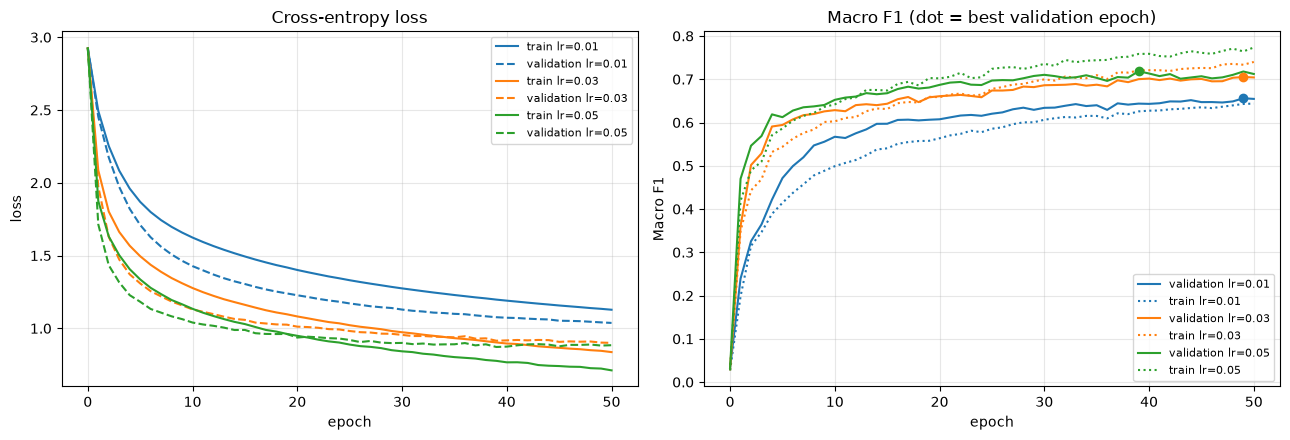

In [15]:
candidates = sorted(RUNS.values(), key=lambda r: (-r["best"]["val_macro_f1"], r["best"]["epoch"], r["lr"]))
selected = candidates[0]
SELECTED_NAME = f"mlp_lr{selected['lr']}"
print(f"Selected: lr={selected['lr']}, epoch {selected['best']['epoch']}, val Macro F1 {selected['best']['val_macro_f1']:.4f}")

# Selected checkpoint (weights + what is needed to use them correctly).
torch.save({"state_dict": selected["best"]["state"], "lr": selected["lr"], "epoch": selected["best"]["epoch"],
            "val_macro_f1": selected["best"]["val_macro_f1"], "label_order": LABELS, "feature_order": FEATURES},
           OUTPUT / "mlp_selected.pt")
pred_selected = pd.read_csv(OUTPUT / f"predictions_validation_{SELECTED_NAME}.csv")
pred_selected.to_csv(OUTPUT / "predictions_validation_mlp_selected.csv", index=False)
RESULTS["mlp_selected"] = RESULTS[SELECTED_NAME]
EXTRA["mlp_selected"] = {**EXTRA[SELECTED_NAME], "notes": f"= {SELECTED_NAME}"}

config = {
    "architecture": f"{len(FEATURES)} -> {HIDDEN} (ReLU) -> {len(LABELS)}",
    "loss": "CrossEntropyLoss", "optimizer": "SGD", "momentum": 0.0, "weight_decay": 0.0,
    "batch_size": BATCH_SIZE, "max_epochs": MAX_EPOCHS, "learning_rates_tried": LEARNING_RATES,
    "seed": SEED, "torch_threads": 1, "updates_per_epoch": UPDATES_PER_EPOCH,
    "selection_rule": "max validation pooled Macro F1 (18 labels, zero_division=0); ties -> earlier epoch, then smaller lr",
    "selected_lr": selected["lr"], "selected_epoch": selected["best"]["epoch"],
    "selected_val_macro_f1": selected["best"]["val_macro_f1"],
    "runtime_s": {str(lr): round(r["runtime_s"], 2) for lr, r in RUNS.items()},
    "initial_state": INIT_PATH.name, "scaler": "scaler.joblib", "label_map": "label_map.json",
    "feature_order": FEATURES, "label_order": LABELS,
    "train_users": USERS["train"], "validation_users": USERS["validation"],
}
(OUTPUT / "mlp_config.json").write_text(json.dumps(config, indent=2))

# ---- Loss / F1 curves -------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for lr, run in RUNS.items():
    h = run["history"]
    line, = axes[0].plot(h.epoch, h.train_loss, label=f"train lr={lr}")
    axes[0].plot(h.epoch, h.val_loss, "--", color=line.get_color(), label=f"validation lr={lr}")
    axes[1].plot(h.epoch, h.val_macro_f1, color=line.get_color(), label=f"validation lr={lr}")
    axes[1].plot(h.epoch, h.train_macro_f1, ":", color=line.get_color(), label=f"train lr={lr}")
    axes[1].scatter([run["best"]["epoch"]], [run["best"]["val_macro_f1"]], color=line.get_color(), zorder=3)
axes[0].set(title="Cross-entropy loss", xlabel="epoch", ylabel="loss")
axes[1].set(title="Macro F1 (dot = best validation epoch)", xlabel="epoch", ylabel="Macro F1")
for ax in axes:
    ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout()
plt.savefig(OUTPUT / "mlp_loss_curves.png", dpi=150)
plt.show()

## central_validation.csv
One row per model, all scored by the same function on the same validation windows.
mlp_selected is a copy of whichever learning-rate row was selected.

In [16]:
summary_rows = []
for name, res in RESULTS.items():
    row = {"model": name}
    row.update({k: v for k, v in res.items() if not k.startswith("_")})
    row.update(EXTRA.get(name, {}))
    summary_rows.append(row)
central = pd.DataFrame(summary_rows)
central.to_csv(OUTPUT / "central_validation.csv", index=False)
display(central.round(4))

,model,macro_f1,accuracy,mean_user_macro_f1,min_user_macro_f1,max_user_macro_f1,n_windows,n_users,classes_missing_in_truth,classes_never_predicted,notes,runtime_s,iterations,lr,best_epoch,updates_to_best
0,majority,0.0058,0.0556,0.0058,0.0058,0.0058,3060,10,,BCDEFGHIJKLMOPQRS,always predicts A,NaN,NaN,NaN,NaN,NaN
1,logreg,0.6623,0.6742,0.6410,0.4019,0.7986,3060,10,,,"C=1.0, max_iter=1000, convergence_warnings=0",0.62,171.0,NaN,NaN,NaN
2,mlp_lr0.01,0.6561,0.6706,0.6315,0.3974,0.7766,3060,10,,,best-validation checkpoint of 50 epochs,4.29,NaN,0.01,49.0,7154.0
3,mlp_lr0.03,0.7051,0.7127,0.6824,0.4826,0.8139,3060,10,,,best-validation checkpoint of 50 epochs,4.37,NaN,0.03,49.0,7154.0
4,mlp_lr0.05,0.7185,0.7199,0.6941,0.4453,0.8477,3060,10,,,best-validation checkpoint of 50 epochs,4.32,NaN,0.05,39.0,5694.0
5,mlp_selected,0.7185,0.7199,0.6941,0.4453,0.8477,3060,10,,,= mlp_lr0.05,4.32,NaN,0.05,39.0,5694.0


## Error analysis on the validation users

### Confusion matrix of the selected MLP
Rows are the true activity, columns the predicted one. The left plot shows counts; the right plot divides each row
by its total, so the diagonal is the per-class recall.

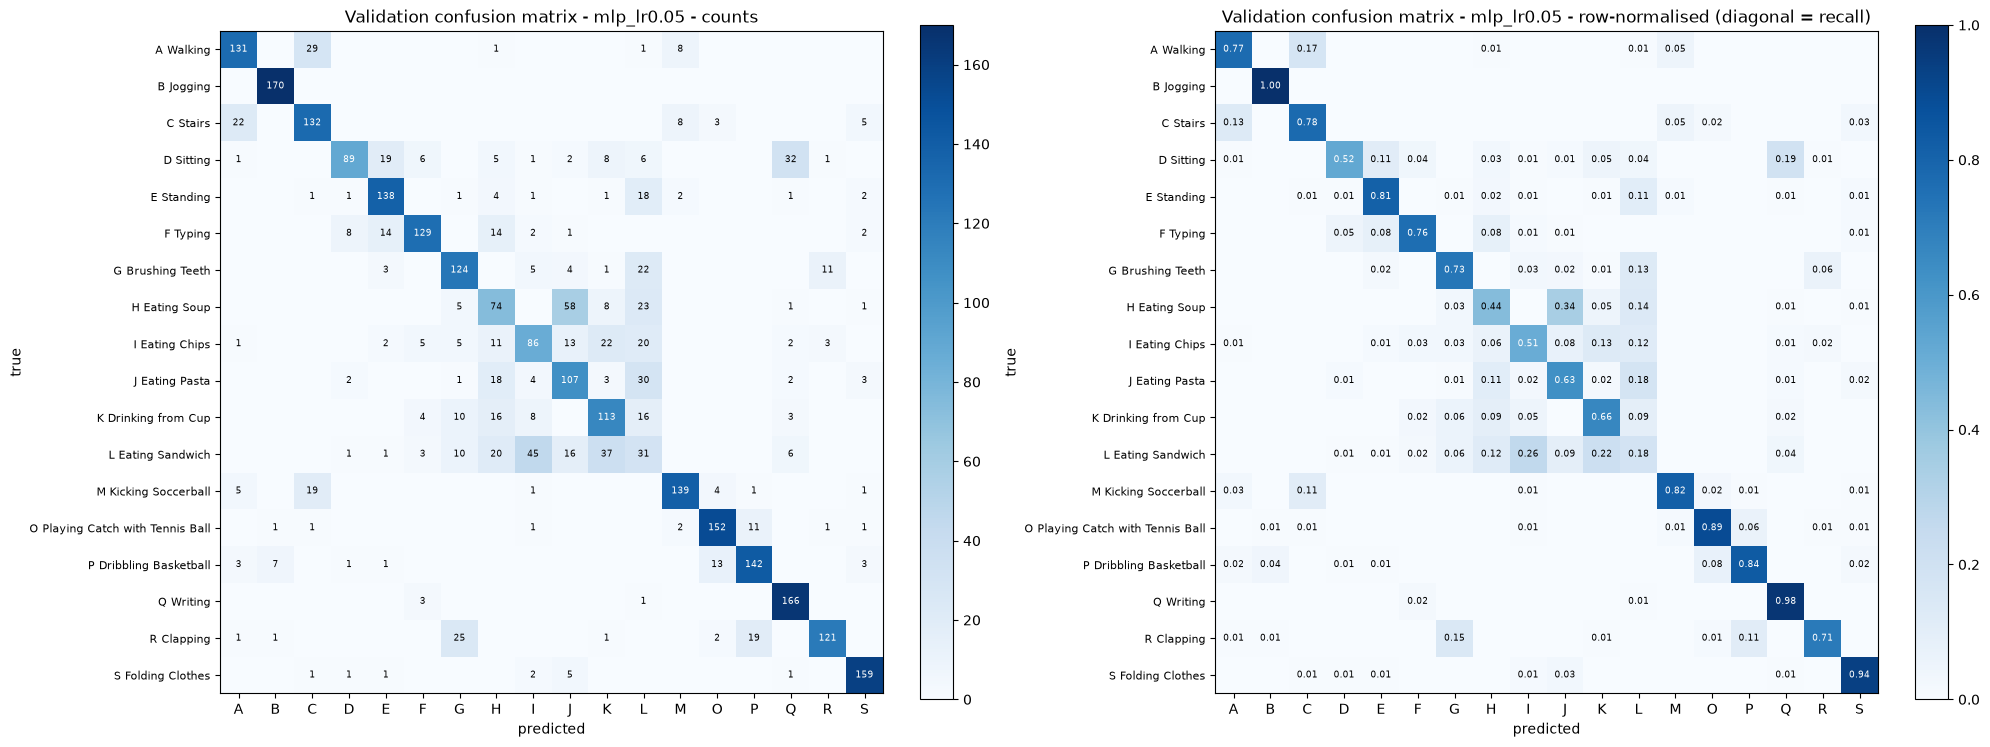

In [17]:
cm = RESULTS["mlp_selected"]["_confusion"]
tick = [f"{c} {ACTIVITY_NAME[c]}" for c in LABELS]
cm_df = pd.DataFrame(cm, index=[f"true_{c}" for c in LABELS], columns=[f"pred_{c}" for c in LABELS])
cm_df.to_csv(OUTPUT / "validation_confusion_matrix_mlp_selected.csv")
pd.DataFrame(RESULTS["logreg"]["_confusion"], index=cm_df.index, columns=cm_df.columns) \
  .to_csv(OUTPUT / "validation_confusion_matrix_logreg.csv")

cm_norm = cm / cm.sum(1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(20, 8.5))
for ax, mat, title, fmt in [(axes[0], cm, "counts", "d"), (axes[1], cm_norm, "row-normalised (diagonal = recall)", ".2f")]:
    im = ax.imshow(mat, cmap="Blues")
    ax.set_xticks(LABEL_IDS, LABELS); ax.set_yticks(LABEL_IDS, tick, fontsize=8)
    ax.set(xlabel="predicted", ylabel="true", title=f"Validation confusion matrix - {SELECTED_NAME} - {title}")
    for i in LABEL_IDS:
        for j in LABEL_IDS:
            v = mat[i, j]
            if v:
                ax.text(j, i, format(v, fmt), ha="center", va="center", fontsize=6.5,
                        color="white" if v > mat.max() / 2 else "black")
    fig.colorbar(im, ax=ax, fraction=.046)
plt.tight_layout()
plt.savefig(OUTPUT / "validation_confusion_matrix_mlp_selected.png", dpi=150)
plt.show()

### Per-class recall, most frequent confusions and per-user scores

In [18]:
support = pd.Series(np.bincount(y_val, minlength=len(LABELS)), index=LABELS, name="val_windows")
recall_table = pd.DataFrame({"name": [ACTIVITY_NAME[c] for c in LABELS], "val_windows": support,
                             **{f"recall_{m}": RESULTS[m]["_per_class_recall"] for m in ["majority", "logreg", "mlp_selected"]}})
recall_table.to_csv(OUTPUT / "validation_per_class_recall.csv", index_label="code")
display(recall_table.sort_values("recall_mlp_selected").round(3))

# Off-diagonal cells of the confusion matrix, largest first.
conf_pairs = pd.DataFrame([{"true": LABELS[i], "pred": LABELS[j],
                            "true_name": ACTIVITY_NAME[LABELS[i]], "pred_name": ACTIVITY_NAME[LABELS[j]],
                            "count": int(cm[i, j]), "share_of_true_class": cm[i, j] / cm[i].sum()}
                           for i in LABEL_IDS for j in LABEL_IDS if i != j and cm[i, j] > 0])
conf_pairs = conf_pairs.sort_values("count", ascending=False).reset_index(drop=True)
conf_pairs.to_csv(OUTPUT / "validation_top_confusions_mlp_selected.csv", index=False)
display(conf_pairs.head(10).round(3))

# How many of the errors stay inside the "eating / drinking" family (H, I, J, K, L)?
EATING = {"H", "I", "J", "K", "L"}
n_errors = int(cm.sum() - np.trace(cm))
n_eating_errors = int(conf_pairs[conf_pairs.true.isin(EATING) & conf_pairs.pred.isin(EATING)]["count"].sum())
print(f"Errors: {n_errors} of {cm.sum()} windows; {n_eating_errors} ({n_eating_errors / max(n_errors, 1):.0%}) "
      f"are one eating/drinking activity mistaken for another")

per_user = pd.DataFrame({m: RESULTS[m]["_per_user_f1"] for m in ["logreg", "mlp_selected"]})
per_user.index.name = "Subject_ID"
per_user.to_csv(OUTPUT / "validation_per_user_macro_f1.csv")
display(per_user.sort_values("mlp_selected").round(3).T)

,name,val_windows,recall_majority,recall_logreg,recall_mlp_selected
L,Eating Sandwich,170,0.0,0.159,0.182
H,Eating Soup,170,0.0,0.406,0.435
I,Eating Chips,170,0.0,0.376,0.506
D,Sitting,170,0.0,0.459,0.524
J,Eating Pasta,170,0.0,0.641,0.629
K,Drinking from Cup,170,0.0,0.565,0.665
R,Clapping,170,0.0,0.771,0.712
G,Brushing Teeth,170,0.0,0.759,0.729
F,Typing,170,0.0,0.776,0.759
A,Walking,170,1.0,0.818,0.771


,true,pred,true_name,pred_name,count,share_of_true_class
0,H,J,Eating Soup,Eating Pasta,58,0.341
1,L,I,Eating Sandwich,Eating Chips,45,0.265
2,L,K,Eating Sandwich,Drinking from Cup,37,0.218
3,D,Q,Sitting,Writing,32,0.188
4,J,L,Eating Pasta,Eating Sandwich,30,0.176
5,A,C,Walking,Stairs,29,0.171
6,R,G,Clapping,Brushing Teeth,25,0.147
7,H,L,Eating Soup,Eating Sandwich,23,0.135
8,G,L,Brushing Teeth,Eating Sandwich,22,0.129
9,C,A,Stairs,Walking,22,0.129


Errors: 857 of 3060 windows; 368 (43%) are one eating/drinking activity mistaken for another


Subject_ID,1622,1644,1603,1635,1619,1630,1611,1606,1615,1610
logreg,0.402,0.426,0.489,0.685,0.749,0.728,0.633,0.742,0.758,0.799
mlp_selected,0.445,0.502,0.526,0.724,0.735,0.782,0.785,0.792,0.801,0.848


## Diagnostics

These checks answer two questions from the work plan:

* **If learning looks poor:** is the label order right, is the feature order right, and can the model at least
  overfit a tiny training subset? (If it cannot memorise ~90 windows, something in the pipeline is broken.)
* **If scores look unexpectedly strong:** is there identity leakage (the same person in two splits) or duplicate windows?

In [19]:
DIAG = {}

# --- 1. Label order --------------------------------------------------------------------
# a) the label map on disk is exactly the frozen order; b) codes -> IDs -> codes round-trips;
# c) the saved predictions decode to the same codes; d) recall from the confusion matrix = recall_score.
saved_map = json.loads((OUTPUT / "label_map.json").read_text())
assert [d["code"] for d in saved_map["labels"]] == LABELS and [d["id"] for d in saved_map["labels"]] == LABEL_IDS
assert (validation["Activity_Code"].to_numpy() == np.array(LABELS)[y_val]).all()
p = pd.read_csv(OUTPUT / "predictions_validation_mlp_selected.csv")
assert (p.pred_code == np.array(LABELS)[p.pred_id]).all() and (p.true_code == np.array(LABELS)[p.true_id]).all()
assert np.allclose(np.diag(cm) / cm.sum(1), RESULTS["mlp_selected"]["_per_class_recall"].to_numpy())
DIAG["label_order"] = "pass"

# --- 2. Feature order ------------------------------------------------------------------
# The scaler remembers the column names it was fitted on; they must equal the allowlist, in order.
assert list(scaler.feature_names_in_) == FEATURES == pd.read_csv(FEATURE_LIST)["features"].tolist()
assert initial_model.net[0].in_features == len(FEATURES)
assert not set(FEATURES) & {"Subject_ID", "window_id", "t_start", "occ", "pair_id", "y"}   # no identity / time columns
DIAG["feature_order"] = "pass"

# --- 3. Tiny training-subset overfit -------------------------------------------------
# 5 training windows per class (90 total). Starting from the shared initial weights, a working
# pipeline should push training accuracy close to 100%. This is a sanity check only: the
# settings here (lr, epochs) are NOT used for model selection.
tiny_idx = train.groupby("y").sample(n=5, random_state=SEED).index.to_numpy().copy()   # .copy(): writable array for torch
Xt, yt = X_train_t[tiny_idx], y_train_t[tiny_idx]
tiny = MLP(); tiny.load_state_dict(torch.load(INIT_PATH))
opt = torch.optim.SGD(tiny.parameters(), lr=0.1, momentum=0.0)
tiny_loader = DataLoader(TensorDataset(Xt, yt), batch_size=BATCH_SIZE, shuffle=True, generator=torch.Generator().manual_seed(SEED))
for epoch in range(1000):
    tiny.train()
    for xb, yb in tiny_loader:
        opt.zero_grad(); loss_fn(tiny(xb), yb).backward(); opt.step()
tiny_acc = (predict_logits(tiny, Xt).argmax(1) == yt).float().mean().item()
tiny_loss = loss_fn(predict_logits(tiny, Xt), yt).item()
print(f"Tiny-subset overfit: {len(tiny_idx)} windows, training accuracy {tiny_acc:.3f}, loss {tiny_loss:.4f}")
DIAG["tiny_overfit"] = f"{'pass' if tiny_acc >= 0.95 else 'FAIL'} (train accuracy {tiny_acc:.3f}, loss {tiny_loss:.4f}, 90 windows, lr 0.1, 1000 epochs)"

# --- 4. Leakage ------------------------------------------------------------------------
# Identity leakage: no participant in more than one split (checked in Step 1b, re-checked here).
assert not set(users_train) & set(users_val)
DIAG["identity_leakage"] = "pass (train and validation participants are disjoint; test users not loaded)"
DIAG["duplicate_windows"] = (f"pass ({DUPLICATE_SUMMARY['windows_in_duplicate_groups']} windows in identical-feature groups, "
                             f"{DUPLICATE_SUMMARY['groups_spanning_splits']} groups spanning splits)")

# "Unexpectedly strong" flag: very high validation scores on unseen people would be suspicious.
best_f1 = RESULTS["mlp_selected"]["macro_f1"]
DIAG["strong_score_flag"] = ("CHECK - validation Macro F1 above 0.95 on unseen people" if best_f1 > 0.95
                             else f"not triggered (selected validation Macro F1 {best_f1:.3f})")

# Majority baseline must sit at the floor; real models must clearly beat it.
assert RESULTS["logreg"]["macro_f1"] > 2 * RESULTS["majority"]["macro_f1"]
assert RESULTS["mlp_selected"]["macro_f1"] > 2 * RESULTS["majority"]["macro_f1"]
DIAG["beats_majority"] = "pass"

for k, v in DIAG.items():
    print(f"{k:<18}: {v}")

Tiny-subset overfit: 90 windows, training accuracy 1.000, loss 0.0460
label_order       : pass
feature_order     : pass
tiny_overfit      : pass (train accuracy 1.000, loss 0.0460, 90 windows, lr 0.1, 1000 epochs)
identity_leakage  : pass (train and validation participants are disjoint; test users not loaded)
duplicate_windows : pass (0 windows in identical-feature groups, 0 groups spanning splits)
strong_score_flag : not triggered (selected validation Macro F1 0.719)
beats_majority    : pass


## Write error_analysis file
The report is generated from the numbers above.

In [20]:
sel_hist = RUNS[selected["lr"]]["history"].set_index("epoch")
sel_epoch = selected["best"]["epoch"]
train_f1_sel = sel_hist.loc[sel_epoch, "train_macro_f1"]
worst = recall_table.sort_values("recall_mlp_selected").head(5)
best_cls = recall_table.sort_values("recall_mlp_selected", ascending=False).head(3)
pu = per_user["mlp_selected"]
per_class_txt = str(int(support.min())) if support.min() == support.max() else f"{int(support.min())}-{int(support.max())}"

# Interpretation sentences are chosen from the numbers, so they stay true if results change.
gap = train_f1_sel - selected["best"]["val_macro_f1"]
if gap < 0.05:
    gap_txt = ("Training and validation scores are close, so the MLP is **underfitting** (limited by the features "
               "and/or the training budget) rather than memorising the training people.")
else:
    gap_txt = ("Training is clearly better than validation, so a large part of the error comes from "
               "generalising to **new people** (person-to-person heterogeneity).")
near_cap = [lr for lr, r in RUNS.items() if r["best"]["epoch"] >= MAX_EPOCHS - 5]
cap_txt = (f"The best epoch for lr={', '.join(map(str, near_cap))} is within 5 epochs of the {MAX_EPOCHS}-epoch cap: "
           "validation Macro F1 was still rising, so more epochs would probably help. The budget is fixed by the "
           "protocol, so we report this rather than extend it." if near_cap else
           "Both runs peaked well before the epoch cap.")

def md_table(df):
    # Minimal markdown table writer (avoids an extra dependency).
    cols = list(df.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for r in df.astype(object).itertuples(index=False):   # astype(object) keeps ints as ints
        lines.append("| " + " | ".join(f"{v:.3f}" if isinstance(v, float) else str(v) for v in r) + " |")
    return "\n".join(lines)

summary_md = central[["model", "macro_f1", "accuracy", "mean_user_macro_f1", "min_user_macro_f1", "max_user_macro_f1"]]
lr_md = pd.DataFrame([{"lr": lr, "best_epoch": r["best"]["epoch"], "best_val_macro_f1": r["best"]["val_macro_f1"],
                       "final_epoch_val_macro_f1": r["history"].val_macro_f1.iloc[-1],
                       "updates_to_best": r["best"]["epoch"] * UPDATES_PER_EPOCH, "runtime_s": round(r["runtime_s"], 1)}
                      for lr, r in RUNS.items()])

report = f"""# Error analysis - Week 3 centralised baselines (validation users only)

Generated by `NCP-WISDM-Baselines.ipynb`. Watch accelerometer + gyroscope, 30 features, 10 s windows.
Train: {len(USERS['train'])} users / {len(train)} windows. Validation: {len(USERS['validation'])} users / {len(validation)} windows
(every validation user has all 18 classes; {per_class_txt} validation windows per class).
Test users ({N_TEST_USERS}) were **not** scored.

## Summary
Pooled Macro F1 uses all 18 label IDs and `zero_division=0`; mean per-user Macro F1 is the unweighted mean over validation users.

{md_table(summary_md)}

## Model selection (MLP)
{md_table(lr_md)}

Selected **lr={selected['lr']}, epoch {sel_epoch}** (highest validation Macro F1; ties -> earlier epoch).
At that epoch training Macro F1 is {train_f1_sel:.3f} vs validation {selected['best']['val_macro_f1']:.3f}
(gap {gap:.3f}). {gap_txt}

{cap_txt}
Curves: `mlp_loss_curves.png`; full history: `mlp_history.csv`.

Logistic regression: {logreg_iters} / {LOGREG_MAX_ITER} iterations, convergence warnings: {len(convergence_warnings)}.
Training Macro F1 {train_f1_logreg:.3f} vs validation {RESULTS['logreg']['macro_f1']:.3f}.

## Per-class recall (selected MLP)
Weakest classes:

{md_table(worst.reset_index().rename(columns={'index': 'code'})[['code', 'name', 'val_windows', 'recall_logreg', 'recall_mlp_selected']])}

Strongest: {', '.join(f"{c} {r['name']} ({r['recall_mlp_selected']:.2f})" for c, r in best_cls.iterrows())}.
Classes never predicted by the selected MLP: {RESULTS['mlp_selected']['classes_never_predicted'] or 'none'}.

## Most frequent confusions (selected MLP)
{md_table(conf_pairs.head(10)[['true', 'true_name', 'pred', 'pred_name', 'count', 'share_of_true_class']])}

{n_eating_errors} of {n_errors} errors ({n_eating_errors / max(n_errors, 1):.0%}) are one eating/drinking activity (H, I, J, K, L)
predicted as another. These activities share the same hand-to-mouth wrist motion, and simple per-window statistics
(mean, std, min, max, RMS) carry little information to separate them.

## Per-user Macro F1 (selected MLP)
Mean {pu.mean():.3f}, range {pu.min():.3f} (user {pu.idxmin()}) to {pu.max():.3f} (user {pu.idxmax()}), std {pu.std():.3f}.
Per-user scores: `validation_per_user_macro_f1.csv`. The spread between people is the heterogeneity that the federated
and personalisation experiments will have to deal with.

## Diagnostics
""" + "\n".join(f"- **{k}**: {v}" for k, v in DIAG.items()) + f"""
- **scaler**: fitted on the {len(train)} training windows only; reused unchanged for validation.

## Files
`central_validation.csv`, `logreg.joblib`, `mlp_initial_state.pt`, `mlp_selected.pt`, `mlp_lr*_best.pt`, `mlp_config.json`,
`mlp_history.csv`, `mlp_loss_curves.png`, `scaler.joblib`, `label_map.json`, `predictions_validation_*.csv`,
`validation_confusion_matrix_*.csv/.png`, `validation_per_class_recall.csv`, `validation_per_user_macro_f1.csv`.

## Notes for the check-in
- (add your own interpretation here)
"""
(OUTPUT / "error_analysis.md").write_text(report, encoding="utf-8")
print(report)

# Error analysis - Week 3 centralised baselines (validation users only)

Generated by `NCP-WISDM-Baselines.ipynb`. Watch accelerometer + gyroscope, 30 features, 10 s windows.
Train: 31 users / 9321 windows. Validation: 10 users / 3060 windows
(every validation user has all 18 classes; 170 validation windows per class).
Test users (10) were **not** scored.

## Summary
Pooled Macro F1 uses all 18 label IDs and `zero_division=0`; mean per-user Macro F1 is the unweighted mean over validation users.

| model | macro_f1 | accuracy | mean_user_macro_f1 | min_user_macro_f1 | max_user_macro_f1 |
|---|---|---|---|---|---|
| majority | 0.006 | 0.056 | 0.006 | 0.006 | 0.006 |
| logreg | 0.662 | 0.674 | 0.641 | 0.402 | 0.799 |
| mlp_lr0.01 | 0.656 | 0.671 | 0.631 | 0.397 | 0.777 |
| mlp_lr0.03 | 0.705 | 0.713 | 0.682 | 0.483 | 0.814 |
| mlp_lr0.05 | 0.719 | 0.720 | 0.694 | 0.445 | 0.848 |
| mlp_selected | 0.719 | 0.720 | 0.694 | 0.445 | 0.848 |

## Model selection (MLP)
| lr | best_epoch | best_val

## Step 11 - Acceptance check

"Ready to proceed when: metrics can be recomputed from saved predictions and the selected checkpoint is supported by a
validation history." This cell re-loads everything **from disk only** and proves both statements.

In [21]:
saved_central = pd.read_csv(OUTPUT / "central_validation.csv")

# 1. Recompute every row of central_validation.csv from its saved prediction file.
for _, row in saved_central.iterrows():
    p = pd.read_csv(OUTPUT / f"predictions_validation_{row.model}.csv")
    r = evaluate(p.true_id, p.pred_id, p.Subject_ID)
    for metric in ["macro_f1", "accuracy", "mean_user_macro_f1"]:
        assert np.isclose(r[metric], row[metric]), (row.model, metric)
print("OK: every metric in central_validation.csv recomputes from the saved predictions")

# 2. The saved scaler + logistic model reproduce the saved logistic predictions from raw features.
sc, lr_model = joblib.load(OUTPUT / "scaler.joblib"), joblib.load(OUTPUT / "logreg.joblib")
p = pd.read_csv(OUTPUT / "predictions_validation_logreg.csv")
assert (lr_model.predict(sc.transform(validation[FEATURES])) == p.pred_id).all()
print("OK: scaler.joblib + logreg.joblib reproduce the logistic predictions")

# 3. The selected checkpoint reproduces the saved MLP predictions, and its score is the best in the validation history.
ckpt = torch.load(OUTPUT / "mlp_selected.pt")
m = MLP(); m.load_state_dict(ckpt["state_dict"])
Xv = torch.tensor(sc.transform(validation[FEATURES]), dtype=torch.float32)
p = pd.read_csv(OUTPUT / "predictions_validation_mlp_selected.csv")
assert (predict_logits(m, Xv).argmax(1).numpy() == p.pred_id).all()
hist = pd.read_csv(OUTPUT / "mlp_history.csv")
h = hist[(hist.lr == ckpt["lr"]) & (hist.epoch >= 1)]
assert np.isclose(h.loc[h.epoch == ckpt["epoch"], "val_macro_f1"].item(), ckpt["val_macro_f1"])
assert np.isclose(hist.loc[hist.epoch >= 1, "val_macro_f1"].max(), ckpt["val_macro_f1"])
assert ckpt["epoch"] == h.loc[np.isclose(h.val_macro_f1, h.val_macro_f1.max()), "epoch"].min()  # earliest best epoch
assert ckpt["label_order"] == LABELS and ckpt["feature_order"] == FEATURES
print(f"OK: mlp_selected.pt (lr={ckpt['lr']}, epoch {ckpt['epoch']}) reproduces its predictions and is the "
      f"earliest best epoch in mlp_history.csv")

# 4. The initial state on disk is the one both runs started from (re-create with the seed and compare).
set_seed(SEED)
fresh = MLP().state_dict()
init = torch.load(OUTPUT / "mlp_initial_state.pt")
assert all(torch.equal(fresh[k], init[k]) for k in fresh)
print("OK: mlp_initial_state.pt is reproducible from seed 42")

# 5. Every required submission file exists.
required = ["central_validation.csv", "logreg.joblib", "mlp_initial_state.pt", "mlp_selected.pt",
            "scaler.joblib", "label_map.json", "validation_confusion_matrix_mlp_selected.csv",
            "validation_confusion_matrix_mlp_selected.png", "error_analysis.md"]
missing = [f for f in required if not (OUTPUT / f).exists()]
assert not missing, missing
print("OK: all submission files present ->", ", ".join(required))

OK: every metric in central_validation.csv recomputes from the saved predictions
OK: scaler.joblib + logreg.joblib reproduce the logistic predictions
OK: mlp_selected.pt (lr=0.05, epoch 39) reproduces its predictions and is the earliest best epoch in mlp_history.csv
OK: mlp_initial_state.pt is reproducible from seed 42
OK: all submission files present -> central_validation.csv, logreg.joblib, mlp_initial_state.pt, mlp_selected.pt, scaler.joblib, label_map.json, validation_confusion_matrix_mlp_selected.csv, validation_confusion_matrix_mlp_selected.png, error_analysis.md
